<a href="https://colab.research.google.com/github/Bhat1801Pranav/garbage-classification-project/blob/main/361.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files
files.upload()


Saving kaggle (1).json to kaggle (1) (2).json


{'kaggle (1) (2).json': b'{"username":"pranavdbhat2005","key":"b23e1409fa1073c14d7e0adb5bc2c60b"}'}

In [6]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d asdasdasasdas/garbage-classification
!unzip -q garbage-classification.zip -d garbage_data

Dataset URL: https://www.kaggle.com/datasets/asdasdasasdas/garbage-classification
License(s): copyright-authors
100% 82.0M/82.0M [00:00<00:00, 119MB/s]



In [7]:
import os

data_dir = "garbage_data"
for root, dirs, files in os.walk(data_dir):
    level = root.replace(data_dir, '').count(os.sep)
    if level < 2:
        print(root)

garbage_data
garbage_data/garbage classification
garbage_data/Garbage classification


In [8]:
for root, dirs, files in os.walk(data_dir):
    if len(files) > 0 and len(dirs) == 0:
        print(root, "->", len(files), "images")


garbage_data/garbage classification/Garbage classification/paper -> 594 images
garbage_data/garbage classification/Garbage classification/cardboard -> 403 images
garbage_data/garbage classification/Garbage classification/trash -> 137 images
garbage_data/garbage classification/Garbage classification/glass -> 501 images
garbage_data/garbage classification/Garbage classification/plastic -> 482 images
garbage_data/garbage classification/Garbage classification/metal -> 410 images
garbage_data/Garbage classification/Garbage classification/paper -> 594 images
garbage_data/Garbage classification/Garbage classification/cardboard -> 403 images
garbage_data/Garbage classification/Garbage classification/trash -> 137 images
garbage_data/Garbage classification/Garbage classification/glass -> 501 images
garbage_data/Garbage classification/Garbage classification/plastic -> 482 images
garbage_data/Garbage classification/Garbage classification/metal -> 410 images


Classes found: ['paper', 'cardboard', 'trash', 'glass', 'plastic', 'metal']


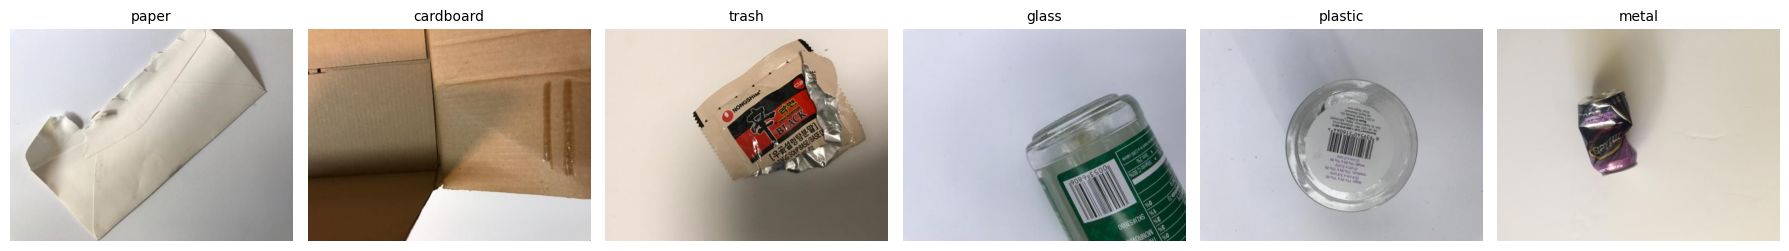

In [9]:
import matplotlib.pyplot as plt
from PIL import Image
import os

base_path = "garbage_data/garbage classification/Garbage classification"
classes = os.listdir(base_path)
print("Classes found:", classes)

fig, axes = plt.subplots(1, len(classes), figsize=(18, 3))
for ax, category in zip(axes, classes):
    folder = os.path.join(base_path, category)
    sample_img = os.listdir(folder)[0]
    img = Image.open(os.path.join(folder, sample_img))
    ax.imshow(img)
    ax.set_title(category, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

Classes found: ['paper', 'cardboard', 'trash', 'glass', 'plastic', 'metal']


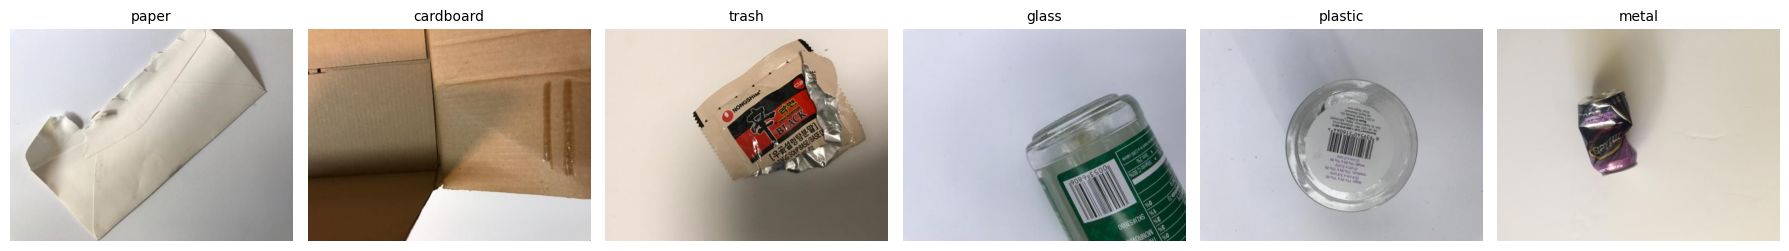

In [10]:
import matplotlib.pyplot as plt
from PIL import Image
import os

base_path = "garbage_data/garbage classification/Garbage classification"
classes = os.listdir(base_path)
print("Classes found:", classes)

fig, axes = plt.subplots(1, len(classes), figsize=(18, 3))
for ax, category in zip(axes, classes):
    folder = os.path.join(base_path, category)
    sample_img = os.listdir(folder)[0]
    img = Image.open(os.path.join(folder, sample_img))
    ax.imshow(img)
    ax.set_title(category, fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
import tensorflow as tf

img_size = (224, 224)   # standard input size for MobileNetV2
batch_size = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    base_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 2527 files belonging to 6 classes.
Using 2022 files for training.
Found 2527 files belonging to 6 classes.
Using 505 files for validation.
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


In [12]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [13]:
import numpy as np

# Recount from folders directly (since train_ds is batched, easier to count original files)
class_counts = {}
for cls in class_names:
    folder = os.path.join(base_path, cls)
    class_counts[cls] = len(os.listdir(folder))

total = sum(class_counts.values())
class_weights = {}
for i, cls in enumerate(class_names):
    class_weights[i] = total / (len(class_names) * class_counts[cls])

print(class_counts)
print(class_weights)


{'cardboard': 403, 'glass': 501, 'metal': 410, 'paper': 594, 'plastic': 482, 'trash': 137}
{0: 1.0450785773366418, 1: 0.8406520292747838, 2: 1.0272357723577237, 3: 0.7090347923681257, 4: 0.873789764868603, 5: 3.0742092457420926}


In [14]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False  # freeze pretrained layers for now

model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(len(class_names), activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
epochs = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    class_weight=class_weights
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 52s 477ms/step - accuracy: 0.5519 - loss: 1.2115 - val_accuracy: 0.7347 - val_loss: 0.7436
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7404 - loss: 0.7154 - val_accuracy: 0.7267 - val_loss: 0.7350
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.7913 - loss: 0.5980 - val_accuracy: 0.7941 - val_loss: 0.5755
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8234 - loss: 0.5079 - val_accuracy: 0.8139 - val_loss: 0.5515
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8343 - loss: 0.4530 - val_accuracy: 0.8198 - val_loss: 0.5211
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8576 - loss: 0.4088 - val_accuracy: 0.8139 - val_loss: 0.5112
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8640 - loss: 0.3808 - val_accuracy: 0.8158 - val_loss: 0.5148
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8823 - loss: 0.3420 - val_accuracy: 0.8455 -

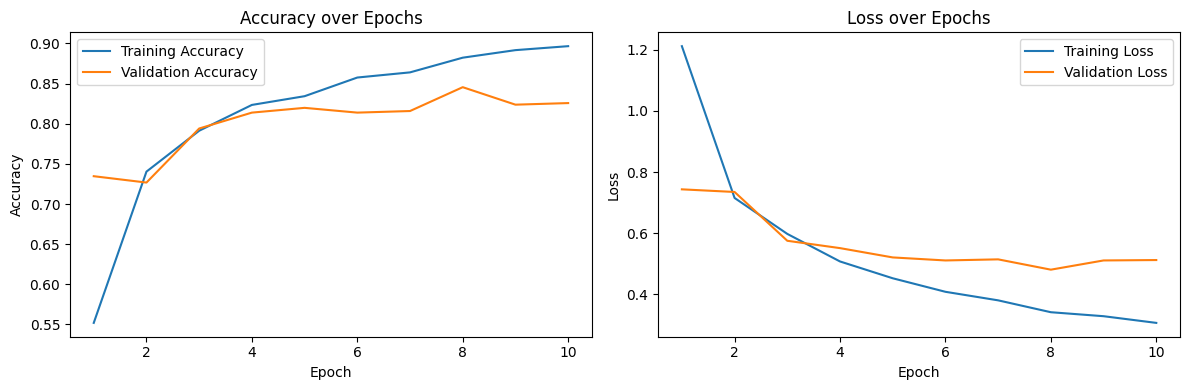

In [16]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.tight_layout()
plt.savefig('training_curves.png')
plt.show()

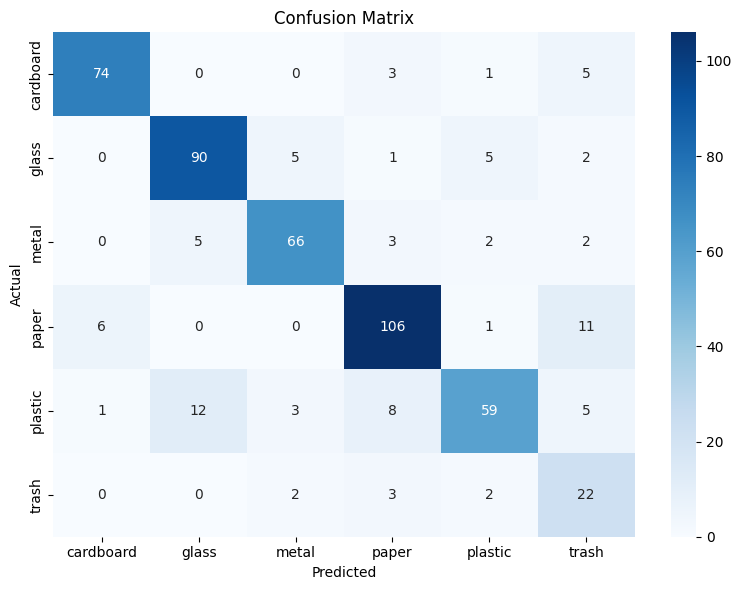

              precision    recall  f1-score   support

   cardboard       0.91      0.89      0.90        83
       glass       0.84      0.87      0.86       103
       metal       0.87      0.85      0.86        78
       paper       0.85      0.85      0.85       124
     plastic       0.84      0.67      0.75        88
       trash       0.47      0.76      0.58        29

    accuracy                           0.83       505
   macro avg       0.80      0.82      0.80       505
weighted avg       0.84      0.83      0.83       505



In [18]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Collect true labels and predictions from the validation set
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

# Build and plot the confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [20]:
import os

save_dir = '/content/drive/MyDrive/PRJ_361_waste_model'
os.makedirs(save_dir, exist_ok=True)

model.save(os.path.join(save_dir, 'waste_classifier_v1.keras'))
print("Model saved to Google Drive!")

Model saved to Google Drive!


In [21]:
import shutil
shutil.copy('training_curves.png', save_dir)
print("Plot saved too!")

Plot saved too!


In [22]:
base_model.trainable = True

# Freeze all layers except the last 30
fine_tune_at = len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print(f"Total layers in base model: {len(base_model.layers)}")
print(f"Trainable from layer {fine_tune_at} onward")

Total layers in base model: 154
Trainable from layer 124 onward


In [23]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 1,534,086 (5.85 MB)

 Non-trainable params: 731,584 (2.79 MB)

In [24]:
fine_tune_epochs = 5
total_epochs = epochs + fine_tune_epochs

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=history.epoch[-1] + 1,
    class_weight=class_weights
)

Epoch 11/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 34s 307ms/step - accuracy: 0.6894 - loss: 0.8094 - val_accuracy: 0.8297 - val_loss: 0.5070
Epoch 12/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8071 - loss: 0.5289 - val_accuracy: 0.8218 - val_loss: 0.5070
Epoch 13/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8660 - loss: 0.4047 - val_accuracy: 0.8198 - val_loss: 0.5007
Epoch 14/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8882 - loss: 0.3267 - val_accuracy: 0.8218 - val_loss: 0.4931
Epoch 15/15
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8991 - loss: 0.2873 - val_accuracy: 0.8297 - val_loss: 0.4865


              precision    recall  f1-score   support

   cardboard       0.87      0.92      0.89        83
       glass       0.81      0.84      0.83       103
       metal       0.90      0.82      0.86        78
       paper       0.88      0.85      0.86       124
     plastic       0.82      0.74      0.78        88
       trash       0.54      0.76      0.63        29

    accuracy                           0.83       505
   macro avg       0.80      0.82      0.81       505
weighted avg       0.84      0.83      0.83       505



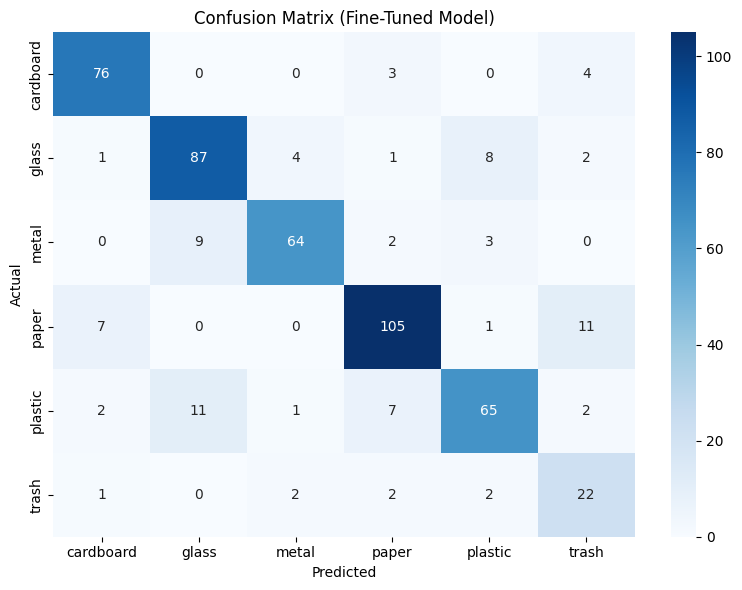

In [25]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Fine-Tuned Model)')
plt.tight_layout()
plt.savefig('confusion_matrix_finetuned.png', dpi=150)
plt.show()

In [26]:
model.save(os.path.join(save_dir, 'waste_classifier_v2_finetuned.keras'))
print("Fine-tuned model saved to Google Drive!")

shutil.copy('confusion_matrix_finetuned.png', save_dir)
print("Confusion matrix saved too!")

Fine-tuned model saved to Google Drive!
Confusion matrix saved too!
